# 2-12 오늘의 이슈 토픽 — 지금 시장에서 뭐가 화제고, 관련 종목은 어떻게 움직였나

**질문 예시:** "지금 경제 뉴스에서 제일 큰 이슈 뭐야? 요약해줘", "그 이슈 관련 종목 주가는?", "SK하이닉스 최근 두 달 주요 이슈를 주가랑 같이 타임라인으로 보여줘"

CHECK API 뉴스는 종목·키워드로 기사를 찾는 방식이라 "무엇이 화제인가"를 직접 주지 않습니다. DeepSearch는 기사를 **토픽(이슈)으로 묶고**,
토픽마다 **AI 요약(인사이트)**까지 줘서 새로 만든 시나리오입니다.

| 단계 | DeepSearch 함수 |
|---|---|
| 지금 뜨는 토픽 | `SearchTrendingTopics(["news"], ["economy"])` — 실행 시점 기준 |
| 토픽 기사 | `GetTrendingTopic(["news"], ["economy"], 토픽uid, count=20)` |
| 토픽 요약·예상 질문 | REST `GET /v1/topic-insight/insight`, `/questions` (같은 API 키) |
| 종목의 과거 이슈 타임라인 | `SearchHistoricalTopics(["news"], ["economy"], "종목", …)` |
| 관련 종목 주가 | `GetStockPrices` |

⚠️ 트렌딩 토픽은 **실행할 때마다 바뀝니다.** 아래 출력은 2026-11-25 새벽(06시대) 실행 결과입니다.

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/2_disclosure_news/12_trending_topics.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        if len(docs) < count:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"          # 주가 기준일 (토픽은 실행 시점)
SECTIONS = ["economy", "tech"]
STOCK = "SK하이닉스"          # 4절 타임라인 종목
T_FROM = "2026-09-15"

## 1. 지금 뜨는 토픽

In [4]:
def trending(section):
    c = _pod(ds(f'SearchTrendingTopics(["news"], ["{section}"])'))["content"]["data"]
    return c["timestamp"], c["topics"]["news"][section]

topics = []
for sec in SECTIONS:
    ts, tl = trending(sec)
    for t in tl:
        topics.append({"섹션": sec, "순위": t["rank"], "uid": t["uid"], "토픽": t["topic"],
                       "기사 수": t["statistics"]["doc_count"],
                       "키워드": ", ".join(k["keyword"] for k in t["keywords"][:5]),
                       "태그 종목": ", ".join(s.get("name", "") for s in t["statistics"]["securities"])})
topics = pd.DataFrame(topics)
print("토픽 기준 시각:", ts)
topics.drop(columns="uid")

토픽 기준 시각: 2026-11-25T06:40:00.000000


,섹션,순위,토픽,기사 수,키워드,태그 종목
0,economy,1,11월 기업심리 한 달 만에 하락…내수 개선·수출 악화,17,"내수기업, 체감경기, 수출기업, 4년6개월, 기업심리",
1,economy,2,보험사 3분기 누적 순익 10.4조…투자손익 악화에 7.8% 감소,10,"10.4조원, 7.8%↓, 19.5%, 당기순이익, 투자손익",
2,economy,3,젠슨 황 복귀에 코스피 6.3% 급등…AI 랠리 지속성은 미지수,9,"삼전닉스, K반도체株, 대기자금, 85조, 전환",
3,economy,4,EU 재생원료 규제 코앞인데…수출기업 55.9% 대응 계획 없어,5,"재생원료, 수출기업, 43.1%, 55.9%, 대응계획",
4,economy,5,롯데마트 내일농장 매출 10%↑…2027년 440여개로 확대,5,"롯데마트, 내일농장, 10%↑, 스마트팜, 프로젝트",
5,economy,6,9년 만에 국내 코인 발행 허용…거래소 지분은 20% 제한,8,"코인거래소, 9년, 스테이블코인, 코인시장, 반발",컴투스홀딩스
6,economy,7,승진 줄인 삼성전자…반도체 70명·HBM·로봇 인재 중용,6,"삼성전자, 로봇, HBM, 131명, 반도체",삼성전자
7,economy,8,美 11월 소비자신뢰지수 103.3…22개월 만에 최고,5,"소비자신뢰지수, 1년10개월, 103.3, 22개월, 소비심리",
8,tech,1,젠슨 황 복귀에도 中 반도체 의혹 계속…美 의회 조사 예고,7,"K반도체, 삼전닉스, 수출통제, 트럼프, 청문회",삼성전자


## 2. 1위 토픽 요약과 예상 질문 (토픽 인사이트)
compute 함수가 아니라 별도 REST 주소지만 같은 키로 됩니다. 요약은 DeepSearch의 생성형 AI가 만든 글이라, 숫자는 원문 기사로 확인하세요.

In [5]:
def insight(kind, section, uid):
    r = requests.get(f"https://api.deepsearch.com/v1/topic-insight/{kind}",
                     params={"type": "trending", "section": section, "topicId": uid, "stream": "false"},
                     headers={"Authorization": "Basic " + _KEY}, timeout=180)
    j = r.json()
    return j.get("data") if j.get("success") else f"(실패: {r.status_code} {str(j)[:200]})"

top1 = topics.iloc[0]
print(f"[{top1['섹션']} 1위] {top1['토픽']}\n")
print(insight("insight", top1["섹션"], top1["uid"]))
print("\n--- 예상 질문 ---")
print(insight("questions", top1["섹션"], top1["uid"]))

[economy 1위] 11월 기업심리 한 달 만에 하락…내수 개선·수출 악화



한국은행 조사에서 11월 전산업 기업심리지수는 103.5로 전월보다 0.7포인트 하락했습니다. 하반기 이어진 상승 흐름이 한 달 만에 꺾였지만, 지수는 기준선인 100을 웃돌아 기업 심리는 장기 평균보다 낙관적인 수준입니다.

제조업과 비제조업이 모두 하락했습니다. 제조업은 식료품·화학제품 판매 부진과 재고 증가, 글로벌 공급 과잉 등이 부담이 됐고, 비제조업은 연료비·인건비 상승과 야외 여가활동 감소가 영향을 미쳤습니다. 내수기업 심리는 반도체·자동차 관련 납품 증가로 개선된 반면, 수출기업은 공급 과잉과 수요 부진 등으로 악화했습니다. 경제심리지수는 99.9로 기준선 아래였지만, 장기 흐름을 보여주는 순환변동치는 100.8로 상승했습니다.

이와 관련하여 다음과 같은 인사이트를 도출할 수 있습니다.

첫째, 전체 지수 하락은 경기 회복의 온기가 업종과 기업 유형별로 고르게 확산되지 않았음을 보여줍니다.

둘째, 내수기업과 수출기업의 흐름이 엇갈려 반도체·자동차 관련 납품 효과와 수출시장 여건을 구분해 살펴볼 필요가 있습니다.

셋째, 재고 누적과 글로벌 공급 과잉은 생산·판매뿐 아니라 기업 수익성에도 부담을 줄 수 있어 재고 관리와 판로 다변화가 중요합니다.

넷째, 기업 심리의 장기 흐름은 기준선을 웃돌지만 단기 체감은 약해졌습니다. 향후에는 비용 부담과 내수 부진이 완화되는지 주의 깊게 볼 필요가 있습니다.

--- 예상 질문 ---


1. 11월 기업심리지수는 얼마나 하락했고, 주요 원인은 무엇인가요?

2. 제조업에서 내수기업과 수출기업의 체감경기는 어떻게 달랐나요?

3. 12월 기업심리지수 전망과 11월 경제심리지수는 어떤 흐름을 보였나요?


## 3. 토픽별 관련 종목과 주가
토픽 기사(최대 20건)에 붙은 **종목 태그**를 세고, 그 종목의 기준일 등락률과 5거래일 수익률을 붙입니다.

In [6]:
rows = []
for _, t in topics.iterrows():
    c = _pod(ds(f'GetTrendingTopic(["news"], ["{t["섹션"]}"], {t["uid"]}, count=20)'))["content"]["data"]
    docs = c["topics"]["news"][t["섹션"]][0].get("docs") or []
    for d in docs:
        for s in d.get("securities") or []:
            if s.get("symbol"):
                rows.append({"섹션": t["섹션"], "순위": t["순위"], "토픽": t["토픽"][:30],
                             "symbol": "KRX:" + str(s["symbol"]), "종목": s.get("name")})
rel = pd.DataFrame(rows)
if rel.empty:
    print("토픽 기사에 종목 태그가 없습니다.")
else:
    rel = rel.groupby(["섹션", "순위", "토픽", "symbol", "종목"]).size().rename("기사 수").reset_index()
    px = stock_prices(rel["symbol"].unique().tolist(), (pd.Timestamp(ASOF) - pd.Timedelta(days=14)).date(), ASOF,
                      columns=["close", "change_rate", "market_cap"])
    last = px.sort_values("date").groupby("symbol").tail(6)
    perf = last.groupby("symbol").apply(lambda g: pd.Series({
        "기준일": g["date"].iloc[-1].date(), "등락률(%)": g["change_rate"].iloc[-1] * 100,
        "5일 수익률(%)": (g["close"].iloc[-1] / g["close"].iloc[0] - 1) * 100,
        "시가총액": krw(g["market_cap"].iloc[-1])}), include_groups=False)
    print(PRICE_NOTICE)
    out = rel.merge(perf, left_on="symbol", right_index=True, how="left").sort_values(["섹션", "순위", "기사 수"], ascending=[True, True, False])
    display(out.drop(columns="symbol").round(2))

※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). 거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).


,섹션,순위,토픽,종목,기사 수,기준일,등락률(%),5일 수익률(%),시가총액
0,economy,6,9년 만에 국내 코인 발행 허용…거래소 지분은 20%,컴투스홀딩스,1,2026-11-24,1.68,-3.20,638억
1,economy,7,승진 줄인 삼성전자…반도체 70명·HBM·로봇 인재 중,삼성전자,4,2026-11-24,6.70,-0.47,1107.3조
2,tech,1,젠슨 황 복귀에도 中 반도체 의혹 계속…美 의회 조사,삼성전자,1,2026-11-24,6.70,-0.47,1107.3조


## 4. 종목의 이슈 타임라인 × 주가
`SearchHistoricalTopics`는 날짜별로 묶인 과거 토픽을 줍니다. 종목 이름으로 찾아 **주가가 크게 움직인 날의 토픽**을 나란히 봅니다.

In [7]:
hist, total = [], None
for page in range(1, 9):                      # 한 번에 30건씩 온다 → 최대 8페이지(240건)
    c = _pod(ds(f'SearchHistoricalTopics(["news"], ["economy"], "{STOCK}", count=30, page={page}, '
                f'date_from={T_FROM}, date_to={ASOF})'))["content"]["data"]
    total = c["total_matches"]
    hist += c["topics"]                       # 과거 토픽은 섹션 구분 없이 바로 목록
    if len(hist) >= total or not c["topics"]:
        break
ht = pd.DataFrame([{"date": pd.Timestamp(t["date"]), "토픽": t["topic"], "score": t["score"]} for t in hist])
c = {"total_matches": total}
print(f"'{STOCK}' 과거 토픽 {c['total_matches']}건 중 {len(ht)}건 받음, {ht['date'].min().date()} ~ {ht['date'].max().date()}")

sym = universe().set_index("name").loc[STOCK, "symbol"]
sp = stock_prices(sym, T_FROM, ASOF, columns=["close", "change_rate"]).set_index("date")
sp["등락률(%)"] = sp["change_rate"] * 100
big = sp.reindex(sp["등락률(%)"].abs().sort_values(ascending=False).index).head(6)
for d, r in big.sort_index().iterrows():
    same = ht[ht["date"] == d].sort_values("score", ascending=False)["토픽"].head(3).tolist()
    print(f"{d.date()}  {r['등락률(%)']:+6.2f}%  | " + (" / ".join(same) if same else "(그날 토픽 없음)"))

'SK하이닉스' 과거 토픽 196건 중 196건 받음, 2026-09-15 ~ 2026-11-24


2026-10-13  -10.09%  | 코스피 5% 넘게 급락 6000선 겨우 지켰다 / 대전 과학기술혁신대상에 HBM 아버지 김정호 교수 / AI 에이전트 성장에 주목 삼성운용 美 투자 ETF 상장
2026-10-15  -11.06%  | 검은 목요일 코스피·코스닥 동반 서킷브레이커 / 美 물가에 금리인상 확률까지 30%대 연준 다시 긴축하나 / 최태원도 물렸다 SK하이닉스 폭락에 회장님 매입가 밑으로
2026-10-28  +10.89%  | SK하이닉스 3분기 영업이익 83조 3년 치 완판
2026-11-05   -9.46%  | 데이터센터 규제 우려 반도체 등 코스피 폭락 / 삼성전자 D램 3분기 점유율 1위 SK하이닉스 2위 / 최태원 SK하이닉스 美 AI 투자법인이사회 의장 맡는다
2026-11-06  -10.44%  | AI 충격에 코스피 장중 5천 붕괴 삼전닉스 대폭락 / 하이닉스 레버리지ETF 고점 대비 90% 넘게 하락했다
2026-11-16   -7.89%  | SK 세계 첫 소부장 팹 공개 반도체 개발 1년 줄인다 / SK하이닉스 올 3분기 누적 설비투자 31조 원 역대 최대 / 외국인 1.6조 투매 코스피 3.59% 급락 마감


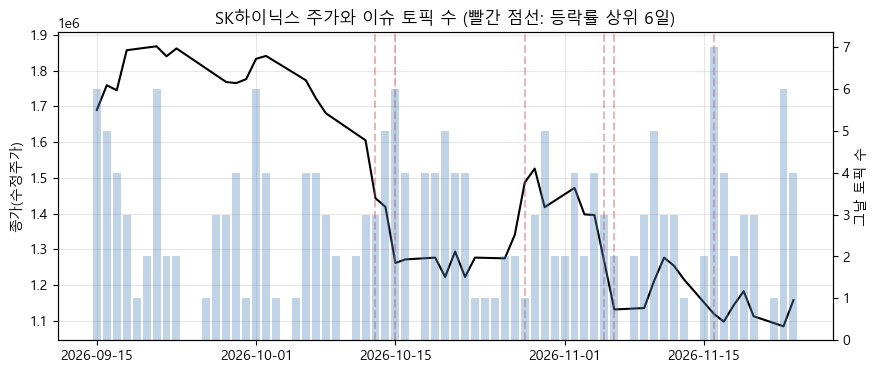

In [8]:
daily = ht.groupby("date").size()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sp.index, sp["close"], color="k")
ax.set_ylabel("종가(수정주가)")
ax2 = ax.twinx()
ax2.bar(daily.index, daily.values, color="#4f81bd", alpha=.35, width=.8)
ax2.set_ylabel("그날 토픽 수")
for d in big.index:
    ax.axvline(d, color="#c0504d", alpha=.4, ls="--")
ax.set_title(f"{STOCK} 주가와 이슈 토픽 수 (빨간 점선: 등락률 상위 6일)"); ax.grid(alpha=.3)

## 결과 읽는 법과 한계
- **트렌딩 토픽은 지금 이 순간의 순위**입니다. 같은 노트북을 다시 실행하면 토픽이 바뀝니다. 과거 특정일의 토픽은 4절처럼 `SearchHistoricalTopics`로 봅니다.
- 토픽 요약(인사이트)은 생성형 AI 요약입니다. 사실관계·숫자는 토픽 기사 원문으로 확인하세요.
- 거시·업황 토픽은 종목 태그가 없는 경우가 많습니다. 관련 종목이 비면 키워드로 `DocumentSearch`를 따로 돌리세요.
- 4절의 토픽은 종목명이 들어간 이슈만 잡히고, 하루에 여러 토픽이 겹칠 수 있습니다. 큰 등락의 "원인"이 아니라 "그날 무슨 이야기가 있었나"로 읽으세요.